In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("retail_sales_dataset.csv")
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [13]:
df.shape


(1000, 9)

In [14]:
df.dtypes

Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

In [19]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [16]:
df.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [18]:
df.describe()


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [21]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [26]:
 df.duplicated().sum()


np.int64(0)

In [27]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [31]:
df["Date"]

0     2023-11-24
1     2023-02-27
2     2023-01-13
3     2023-05-21
4     2023-05-06
         ...    
995   2023-05-16
996   2023-11-17
997   2023-10-29
998   2023-12-05
999   2023-04-12
Name: Date, Length: 1000, dtype: datetime64[ns]

In [32]:
df["Date"].min(), "to", df["Date"].max()


(Timestamp('2023-01-01 00:00:00'), 'to', Timestamp('2024-01-01 00:00:00'))

In [34]:
numeric_columns = df.select_dtypes(include=np.number).columns

stats = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Mode": df[numeric_columns].mode().iloc[0],
    "Standard Deviation": df[numeric_columns].std()
})
stats.round(2)

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00


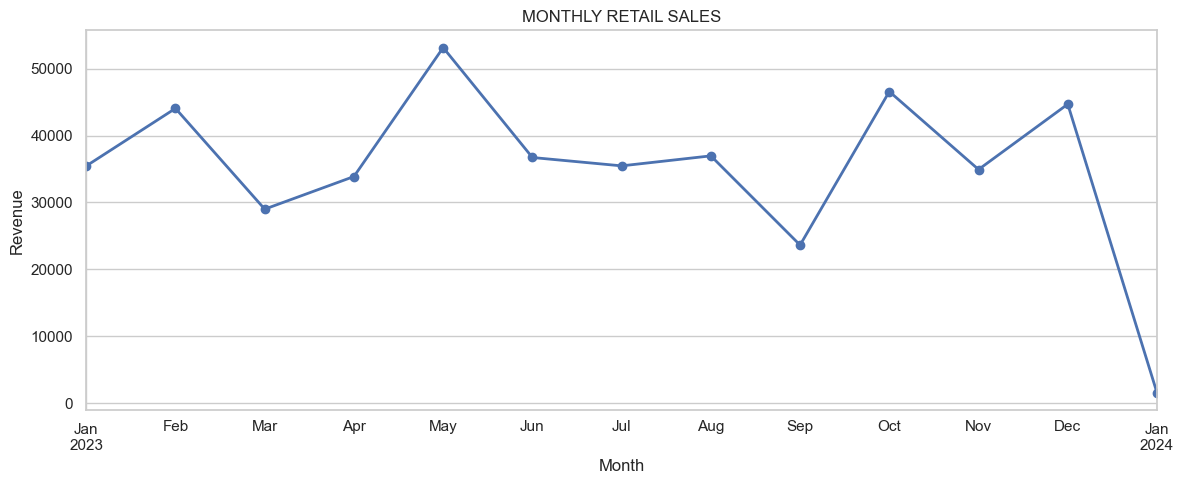

1530

In [57]:
monthly_sales = (df.set_index("Date")["Total Amount"].resample("MS").sum())

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o", linewidth=2)
plt.title("MONTHLY RETAIL SALES")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks
plt.tight_layout()
plt.show()

monthly_sales.idxmax().strftime("%x %Y")
monthly_sales.max()
monthly_sales.idxmin().strftime("%x %Y")
monthly_sales.min()

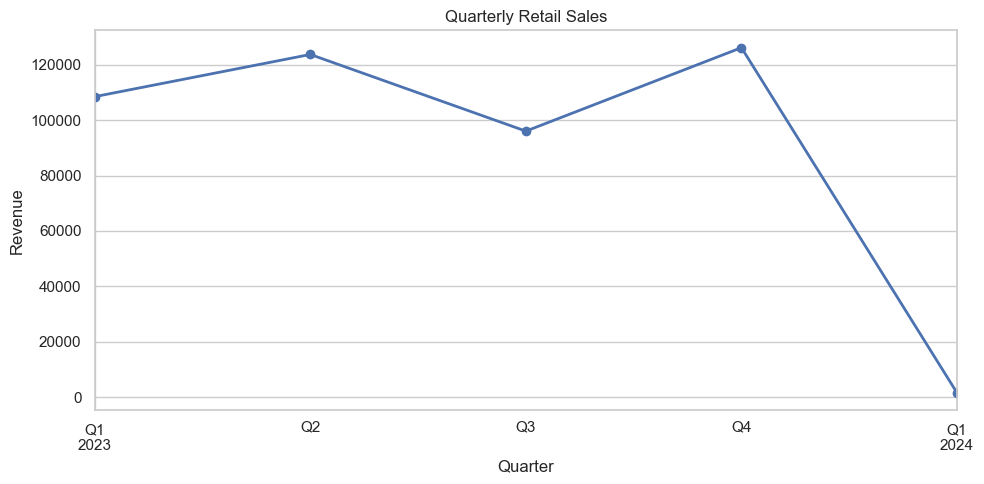

Date
2023-01-01    108500
2023-04-01    123735
2023-07-01     96045
2023-10-01    126190
2024-01-01      1530
Freq: QS-JAN, Name: Total Amount, dtype: int64


In [66]:
quarterly_sales = (df.set_index("Date")["Total Amount"]
                     .resample("QS").sum())

plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind="line", marker="o", linewidth=2)
plt.title("Quarterly Retail Sales")
plt.xlabel("Quarter")
plt.ylabel("Revenue")
plt.xticks
plt.tight_layout()
plt.show()

print(quarterly_sales)

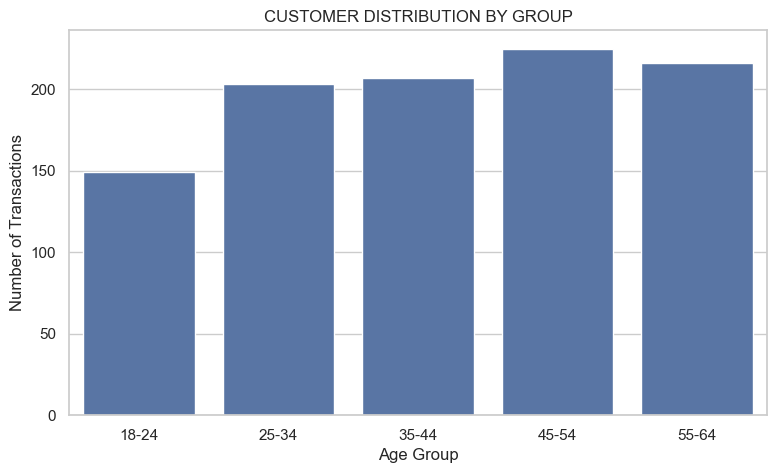

Age Group
18-24    149
25-34    203
35-44    207
45-54    225
55-64    216
Name: count, dtype: int64


In [76]:
age = [17, 24, 34, 44, 54, 64]
age = ["18-24", "25-34", "35-44", "45-54", "55-64"]
df["Age Group"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels)

age_counts = df["Age Group"].value_counts().sort_index()
plt.figure(figsize=(9, 5))
sns.barplot(x=age_counts.index.astype(str), y=age_counts.values)
plt.title("CUSTOMER DISTRIBUTION BY GROUP")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.show()
print(age_counts)

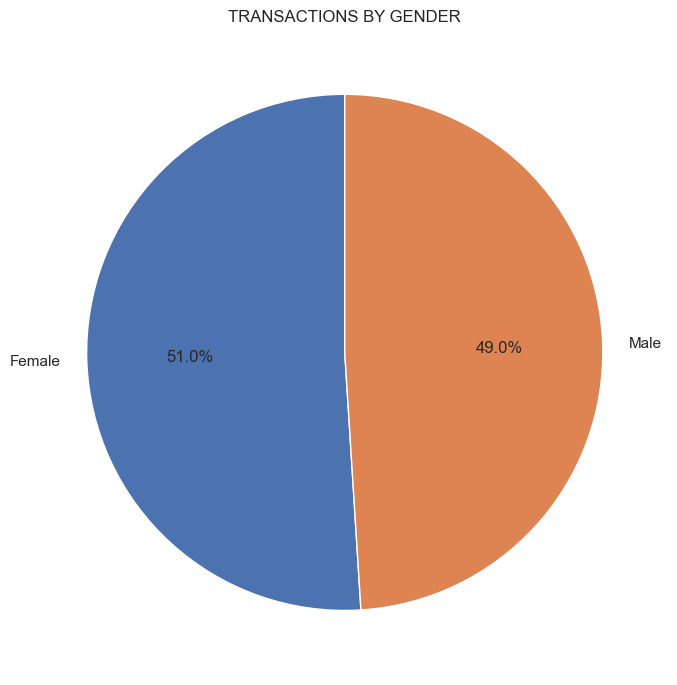

,Transactions,Revenue,Average_Transaction
Gender,,,
Female,510,232840,456.55
Male,490,223160,455.43


In [85]:
gender_counts = df["Gender"].value_counts()
plt.figure(figsize=(7, 8))
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.1f%%",startangle=90)
plt.title("TRANSACTIONS BY GENDER")
plt.tight_layout()
plt.show()
gender_summary = df.groupby("Gender").agg(
    Transactions=("Transaction ID", "count"),
    Revenue=("Total Amount", "sum"),
    Average_Transaction=("Total Amount", "mean")).round(2)
gender_summary

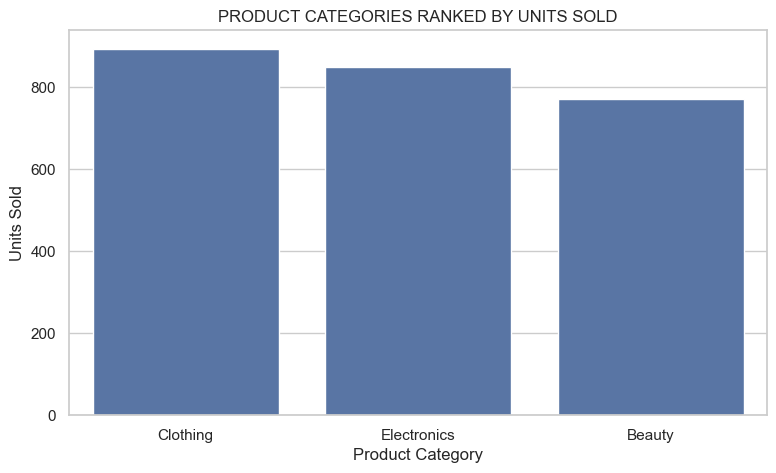

,Transactions,Units_Sold,Revenue
Product Category,,,
Clothing,351,894,155580
Electronics,342,849,156905
Beauty,307,771,143515


In [93]:
category_summary = df.groupby("Product Category").agg(
Transactions=("Transaction ID", "count"),
Units_Sold=("Quantity", "sum"),
Revenue=("Total Amount", "sum")).sort_values("Units_Sold", ascending=False)
top_categories = category_summary.head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_categories.index, y=top_categories["Units_Sold"])
plt.title("PRODUCT CATEGORIES RANKED BY UNITS SOLD")
plt.xlabel("Product Category")
plt.ylabel("Units Sold")
plt.xticks
plt.show()
category_summary

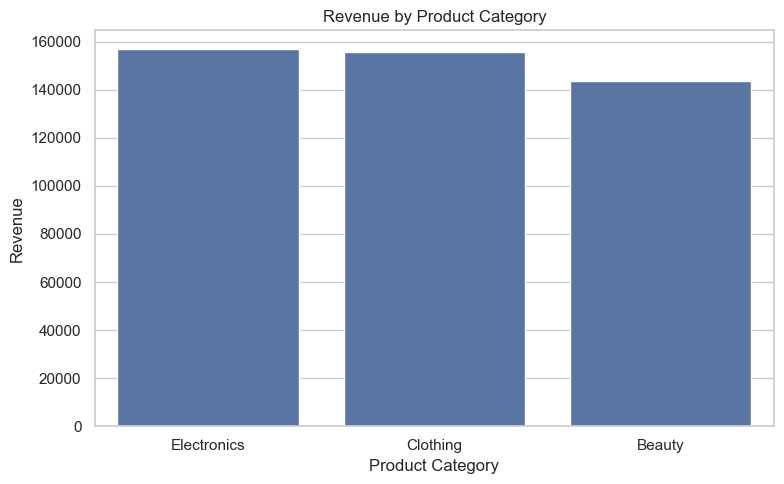

,Revenue,Transactions,Units_Sold
Product Category,,,
Electronics,156905,342,849
Clothing,155580,351,894
Beauty,143515,307,771


In [91]:
category_revenue = category_summary.sort_values("Revenue", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(x=category_revenue.index, y=category_revenue["Revenue"])
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()
category_revenue[["Revenue", "Transactions", "Units_Sold"]]

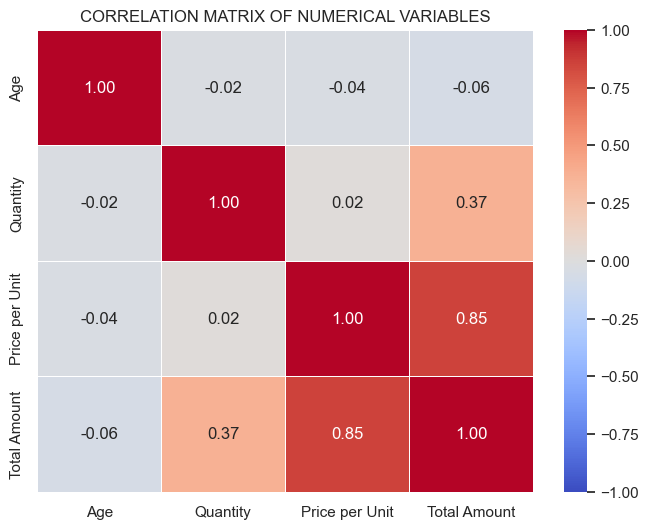

,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


In [112]:
corr_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f",vmin=-1, vmax=1, linewidths=0.5)
plt.title("CORRELATION MATRIX OF NUMERICAL VARIABLES")
plt.show()
corr_matrix

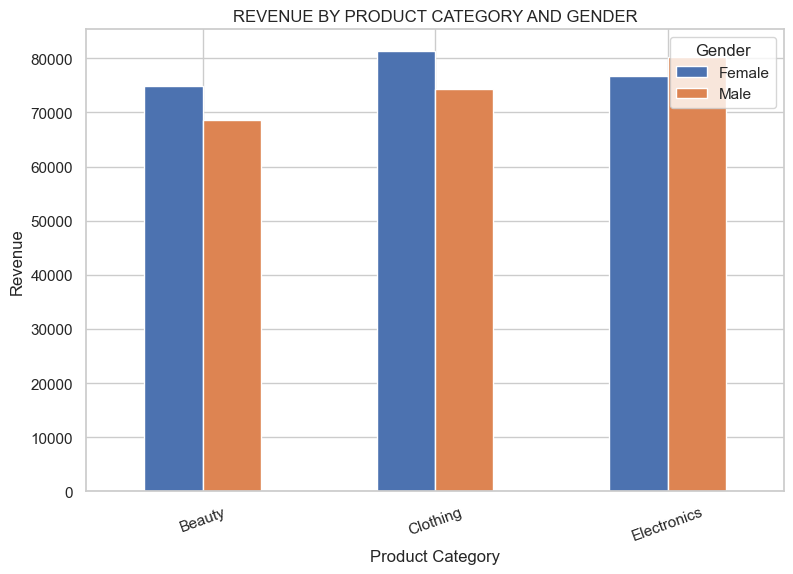

Gender,Female,Male
Product Category,,
Beauty,74830,68685
Clothing,81275,74305
Electronics,76735,80170


In [105]:
gender_category = (df.pivot_table(index="Product Category", columns="Gender",
values="Total Amount", aggfunc="sum",fill_value=0))
gender_category.plot(kind="bar", figsize=(9, 6))
plt.title("REVENUE BY PRODUCT CATEGORY AND GENDER")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=20)
plt.legend(title="Gender")
plt.show()
gender_category